# Part 1 — Embedding-Based Transfer Learning (Word2Vec + IMDB)

**Goal:** take a pretrained `word2vec-google-news-300` model, inspect a few
words, *continue training* (fine-tune) those embeddings on IMDB review text,
and measure how the embedding space shifts.

**Rubric map**
1. Load pretrained Word2Vec &rarr; *Section 2*
2. Top-3 neighbours + cosine sim for `cast, score, plot, screen, review` (pretrained) &rarr; *Section 3*
3. Fine-tune embeddings on IMDB text &rarr; *Sections 4-5*
4. Re-extract top-3 neighbours after fine-tuning &rarr; *Section 6*
5. Both result sets in a table + 2D (t-SNE) shift visualisation for &ge;1 word &rarr; *Sections 7-8*
6. Cosine(original, fine-tuned) per word, table, most/least shifted &rarr; *Section 9*

> **Run this in Google Colab (CPU is fine here).** The pretrained model is
> ~1.6&nbsp;GB and downloads on first use.


## 1. Install & imports

In [1]:
# If a scipy "triu" error appears with older gensim, pin:  gensim>=4.3.3  scipy<1.13  numpy<2
!pip install -q gensim datasets scikit-learn matplotlib pandas


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

from sklearn.manifold import TSNE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

TARGET_WORDS = ["cast", "score", "plot", "screen", "review"]
TOPN = 3


## 2. Load the pretrained Word2Vec model

In [3]:
# ~1.6 GB download the first time, then cached.
pretrained = api.load("word2vec-google-news-300")
print("Loaded pretrained vectors:", len(pretrained), "words,", pretrained.vector_size, "dims")


Loaded pretrained vectors: 3000000 words, 300 dims


## 3. Top-3 neighbours (PRETRAINED)

In [4]:
def neighbour_table(kv, words, topn=TOPN, tag="pretrained"):
    rows = []
    for w in words:
        if w not in kv:
            rows.append({"word": w, "rank": "-", "neighbor": "NOT IN VOCAB",
                         "cosine": np.nan, "model": tag})
            continue
        for rank, (nbr, sim) in enumerate(kv.most_similar(w, topn=topn), start=1):
            rows.append({"word": w, "rank": rank, "neighbor": nbr,
                         "cosine": round(float(sim), 4), "model": tag})
    return pd.DataFrame(rows)

pre_tbl = neighbour_table(pretrained, TARGET_WORDS, tag="pretrained")
pre_tbl


,word,rank,neighbor,cosine,model
0,cast,1,casts,0.7219,pretrained
1,cast,2,casting,0.7188,pretrained
2,cast,3,Cast,0.6638,pretrained
3,score,1,scoring,0.7197,pretrained
4,score,2,scores,0.6596,pretrained
5,score,3,scored,0.6384,pretrained
6,plot,1,plots,0.7625,pretrained
7,plot,2,Plot,0.6524,pretrained
8,plot,3,plotting,0.6328,pretrained
9,screen,1,screens,0.7729,pretrained


## 4. Load & preprocess the IMDB review text

We only need the raw text (unlabeled) to continue-train the embeddings, so we
merge every split into one corpus and tokenise with `simple_preprocess`.

In [5]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")   # canonical id; bare "imdb" alias breaks newer hub
texts = list(imdb["train"]["text"]) + list(imdb["test"]["text"])   # 50k (train+test)
print("Raw reviews:", len(texts))

sentences = [simple_preprocess(t, deacc=True) for t in texts]
sentences = [s for s in sentences if len(s) > 2]
print("Usable tokenised reviews:", len(sentences))

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

C:\Users\Rohil\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Rohil\.cache\huggingface\hub\datasets--stanfordnlp--imdb. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Raw reviews: 50000
Usable tokenised reviews: 50000


## 5. Fine-tune (continue training) the embeddings

Recipe for *transfer learning* on embeddings:
1. Build a fresh skip-gram `Word2Vec` and build its vocab from IMDB.
2. **Warm-start**: overwrite each word's random vector with its pretrained
   Google-News vector (words not in Google-News keep their random init).
3. `train()` for a few epochs &rarr; the vectors move to fit movie-review usage.

Because we warm-start from the pretrained space and only train a few epochs, the
two spaces stay roughly aligned, so `cosine(original, fine-tuned)` for the *same*
word is meaningful (Section 9).

In [6]:
import logging
logging.basicConfig(format="%(asctime)s %(levelname)s %(message)s", level=logging.INFO)

w2v = Word2Vec(
    vector_size=300, window=5, min_count=5, sg=1,
    negative=5, workers=4, seed=RANDOM_STATE, epochs=5,
)
w2v.build_vocab(sentences)
print("IMDB vocab size:", len(w2v.wv))

shared = 0
for word in w2v.wv.index_to_key:
    if word in pretrained:
        w2v.wv.vectors[w2v.wv.key_to_index[word]] = pretrained[word]
        shared += 1
print("Seeded", shared, "/", len(w2v.wv), "from Google-News")

original_vecs = {w: pretrained[w].copy() for w in TARGET_WORDS if w in pretrained}

w2v.train(sentences, total_examples=w2v.corpus_count, epochs=w2v.epochs)
print("Fine-tuning done.")

2026-09-06 21:02:12,549 INFO Word2Vec lifecycle event {'params': 'Word2Vec<vocab=0, vector_size=300, alpha=0.025>', 'datetime': '2026-09-06T21:02:12.549758', 'gensim': '4.4.0', 'python': '3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]', 'platform': 'Windows-11-10.0.26200-SP0', 'event': 'created'}
2026-09-06 21:02:12,552 INFO collecting all words and their counts
2026-09-06 21:02:12,553 INFO PROGRESS: at sentence #0, processed 0 words, keeping 0 word types
2026-09-06 21:02:13,525 INFO PROGRESS: at sentence #10000, processed 2240808 words, keeping 48082 word types
2026-09-06 21:02:14,491 INFO PROGRESS: at sentence #20000, processed 4509634 words, keeping 66124 word types
2026-09-06 21:02:15,475 INFO PROGRESS: at sentence #30000, processed 6746088 words, keeping 78598 word types
2026-09-06 21:02:16,443 INFO PROGRESS: at sentence #40000, processed 8969174 words, keeping 89187 word types
2026-09-06 21:02:17,394 INFO collected 98881 word types

IMDB vocab size: 39157


2026-09-06 21:02:19,603 INFO Word2Vec lifecycle event {'msg': 'training model with 4 workers on 39157 vocabulary and 300 features, using sg=1 hs=0 sample=0.001 negative=5 window=5 shrink_windows=True', 'datetime': '2026-09-06T21:02:19.603489', 'gensim': '4.4.0', 'python': '3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]', 'platform': 'Windows-11-10.0.26200-SP0', 'event': 'train'}


Seeded 32067 / 39157 from Google-News


2026-09-06 21:02:20,631 INFO EPOCH 0 - PROGRESS: at 1.49% examples, 123160 words/s, in_qsize 7, out_qsize 0
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
2026-09-06 21:02:21,662 INFO EPOCH 0 - PROGRESS: at 3.28% examples, 133604 words/s, in_qsize 7, out_qsize 0
2026-09-06 21:02:22,675 INFO EPOCH 0 - PROGRESS: at 5.08% examples, 138087 words/s, in_qsize 7, out_qsize 0
2026-09-06 21:02:23,694 INFO EPOCH 0 - PROGRESS: at 7.06% examples, 143777 words/s, in_qsize 7, out_qsize 0
2026-09-06 21:02:24,829 INFO EPOCH 0 - PROGRESS: at 8.98% examples, 143974 words/s, in_qsize 8, out_qsize 0
2026-09-06 21:02:25,848 INFO EPOCH 0 - PROGRESS: at 10.89% examples, 146435 words/s, in_qsize 7, out_qsize 0
2026-09-06 21:02:26,869 INFO EPOCH 0 - PROGRESS: at 12.64% examples, 147392 words/s, in_qsize 7, out_qsize 0
2026-09-06 21:02:27,965 INFO EPOCH 0 - PROGRESS: at 14.59% examples, 146770 words/s, in_qsize 7, out_qsize 0
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'

Fine-tuning done.


## 6. Top-3 neighbours (FINE-TUNED)

In [7]:
ft_tbl = neighbour_table(w2v.wv, TARGET_WORDS, tag="fine-tuned")
ft_tbl


,word,rank,neighbor,cosine,model
0,cast,1,supporting,0.6397,fine-tuned
1,cast,2,ensemble,0.5825,fine-tuned
2,cast,3,actors,0.5823,fine-tuned
3,score,1,ennio,0.6770,fine-tuned
4,score,2,donaggio,0.6719,fine-tuned
5,score,3,music,0.6588,fine-tuned
6,plot,1,storyline,0.7158,fine-tuned
7,plot,2,story,0.6128,fine-tuned
8,plot,3,plotline,0.6119,fine-tuned
9,screen,1,screens,0.5595,fine-tuned


## 7. Both result sets in one table

In [8]:
combined = pd.concat([pre_tbl, ft_tbl], ignore_index=True)
# pivot to a compact side-by-side view: word x rank -> "neighbor (cos)"
def fmt(r):
    if pd.isna(r["cosine"]):
        return r["neighbor"]
    return f'{r["neighbor"]} ({r["cosine"]:.3f})'
combined["cell"] = combined.apply(fmt, axis=1)
side = combined.pivot_table(index="word", columns=["model", "rank"],
                            values="cell", aggfunc="first")
side = side.reindex(TARGET_WORDS)
side


model           fine-tuned                                      \
rank                     1                 2                 3   
word                                                             
cast    supporting (0.640)  ensemble (0.583)    actors (0.582)   
score        ennio (0.677)  donaggio (0.672)     music (0.659)   
plot     storyline (0.716)     story (0.613)  plotline (0.612)   
screen     screens (0.559)     stage (0.482)  onscreen (0.480)   
review     comment (0.654)   reviews (0.600)   preface (0.576)   

model         pretrained                                         
rank                   1                  2                   3  
word                                                             
cast       casts (0.722)    casting (0.719)        Cast (0.664)  
score    scoring (0.720)     scores (0.660)      scored (0.638)  
plot       plots (0.762)       Plot (0.652)    plotting (0.633)  
screen   screens (0.773)   onscreen (0.612)  LCD_screen (0.560)  
review  reviewed (0.663)  reviewing (0.661)     reviews (0.638)

## 8. Visualise the shift in 2D (t-SNE)

We embed the **original** and **fine-tuned** vector of all 5 words together and
draw an arrow from each word's original position to its fine-tuned position.
(t-SNE is run on the joint set so both points live in the same 2D map.)

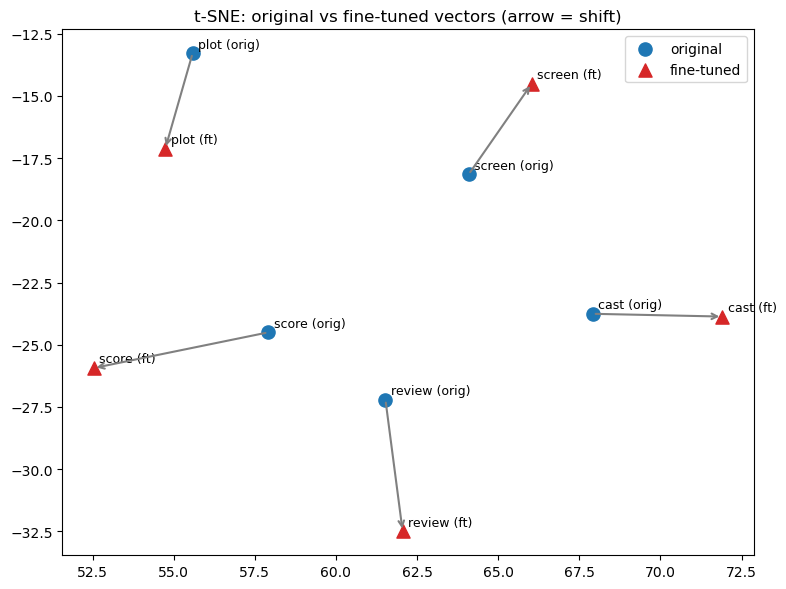

In [9]:
finetuned_vecs = {w: w2v.wv[w].copy() for w in TARGET_WORDS if w in w2v.wv}
words = [w for w in TARGET_WORDS if w in original_vecs and w in finetuned_vecs]

mat, labels, kinds = [], [], []
for w in words:
    mat.append(original_vecs[w]);  labels.append(w + " (orig)");  kinds.append("orig")
    mat.append(finetuned_vecs[w]); labels.append(w + " (ft)");   kinds.append("ft")
mat = np.array(mat, dtype=np.float32)

perp = max(2, min(5, len(mat) - 1))
emb2d = TSNE(n_components=2, perplexity=perp, init="pca",
            random_state=RANDOM_STATE, learning_rate="auto").fit_transform(mat)

plt.figure(figsize=(8, 6))
for i, (lab, k) in enumerate(zip(labels, kinds)):
    x, y = emb2d[i]
    plt.scatter(x, y, c=("tab:blue" if k == "orig" else "tab:red"),
                marker=("o" if k == "orig" else "^"), s=90,
                label=("original" if (k == "orig" and i == 0) else
                       "fine-tuned" if (k == "ft" and i == 1) else None))
    plt.annotate(lab, (x, y), fontsize=9, xytext=(4, 4), textcoords="offset points")

# arrows original -> fine-tuned per word
for i in range(0, len(mat), 2):
    x0, y0 = emb2d[i]; x1, y1 = emb2d[i + 1]
    plt.annotate("", xy=(x1, y1), xytext=(x0, y0),
                 arrowprops=dict(arrowstyle="->", color="gray", lw=1.5))

plt.title("t-SNE: original vs fine-tuned vectors (arrow = shift)")
plt.legend(); plt.tight_layout(); plt.show()


## 9. Cosine(original, fine-tuned) per word — most / least shifted

Cosine close to **1.0** &rarr; the word barely moved. Lower cosine &rarr; bigger
semantic shift on movie-review text.

In [10]:
def cosine(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

shift_rows = []
for w in words:
    c = cosine(original_vecs[w], finetuned_vecs[w])
    shift_rows.append({"word": w, "cosine_orig_vs_ft": round(c, 4),
                       "shift(1-cos)": round(1 - c, 4)})
shift_tbl = pd.DataFrame(shift_rows).sort_values("shift(1-cos)", ascending=False)
display(shift_tbl.reset_index(drop=True))

most  = shift_tbl.iloc[0]["word"]
least = shift_tbl.iloc[-1]["word"]
print(f"Most shifted : {most}")
print(f"Least shifted: {least}")


,word,cosine_orig_vs_ft,shift(1-cos)
0,review,0.4602,0.5398
1,score,0.4785,0.5215
2,cast,0.5902,0.4098
3,plot,0.6311,0.3689
4,screen,0.6486,0.3514


Most shifted : review
Least shifted: screen


### Interpretation

Shift is measured as `1 - cosine(original, fine-tuned)` (higher = moved more):

- **Most shifted — `review` (0.540).** In general news it clusters with
  *reviewed / reviewing* (examining); on IMDB it becomes a viewer's written
  opinion, so neighbours shift to *comment, reviews*.
- **`score` (0.522)** — the clearest *sense change*: from points / tally
  (*scoring, scores, scored*) to the **musical score**, with neighbours
  *ennio, donaggio, music* (film composers Ennio Morricone, Pino Donaggio).
- **`cast` (0.410) and `plot` (0.369)** — moderate; they adopt film-specific
  senses (*supporting, ensemble, actors*; *storyline, story, plotline*) without
  their general meaning being wildly different.
- **Least shifted — `screen` (0.351).** It means a display / showing surface in
  both corpora (*screens, onscreen* persist), so it moved the least.
- In the t-SNE plot the longest arrows are `review` and `score`; the shortest is
  `screen` — matching the table above.
